In [1]:
import numpy as np
import pandas as pd
from os import listdir, path, makedirs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

In [2]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path):
    for name in names:
        file_path = os.path.join(base_path, name, "quantify_genome/output_unique_biotype.csv")
        df = pd.read_csv(file_path, sep=',')
        df_dict[name] = df[df['gene_biotype'].notna()]


def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='gene_biotype', how='left').fillna(0)
    result_df = result_df.rename(columns={'unique_seq_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['gene_biotype'] for name in names]).unique()
    result_df = pd.DataFrame({'gene_biotype': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)

In [3]:
# define the base path for output csv files
base_path = "../../../../3rd_3samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR20723831", "SRR20723832", "SRR20723833"
]

# columns to read from the original CSV files
# read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


#df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total_with_match, base_path)


# filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset3_gene_biotype_count.csv")


DataFrame SRR20723831 has 7 lines.
DataFrame SRR20723832 has 7 lines.
DataFrame SRR20723833 has 7 lines.
{'SRR20723831':      gene_biotype  unique_seq_count
0        misc_RNA             80720
2           ncRNA           3265770
3           other             10419
4  protein_coding          21722080
5      pseudogene            109906
6            rRNA           8993673
7            tRNA            998034, 'SRR20723832':      gene_biotype  unique_seq_count
0        misc_RNA             88978
2           ncRNA           3722189
3           other             11743
4  protein_coding          21775490
5      pseudogene            100505
6            rRNA           9728400
7            tRNA            961736, 'SRR20723833':      gene_biotype  unique_seq_count
0        misc_RNA             93624
2           ncRNA           2668204
3           other              9371
4  protein_coding          20122590
5      pseudogene             99045
6            rRNA          11742447
7            tRNA  

aaa


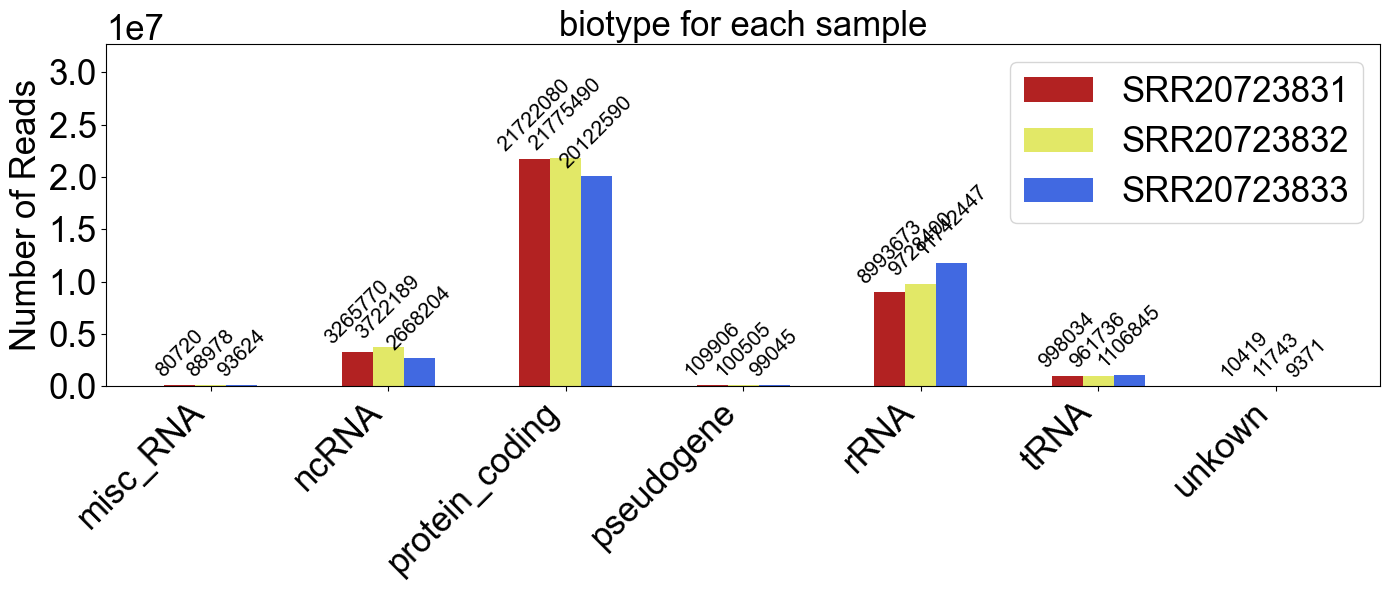

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=25)

arial_font_in = fm.FontProperties(fname="arial.ttf", size=15)
print("aaa")

labels = ["misc_RNA", "ncRNA", "protein_coding", "pseudogene", "rRNA","tRNA","unkown"]


sample_31 = [80720, 3265770, 21722080, 109906, 8993673, 998034,10419]
sample_32 = [88978, 3722189, 21775490, 100505, 9728400, 961736,11743]
sample_33 = [93624, 2668204, 20122590, 99045, 11742447, 1106845,9371]

x = np.arange(len(labels))
width = 0.35  # width of the bars

fig, ax = plt.subplots(figsize=(14, 6))
# bars1 = ax.bar(x - width/2, sample_31, width/2, label='SRR20723831', color='#1f77b4')
# bars2 = ax.bar(x, sample_32, width/2, label='SRR20723832', color='#ff7f0e')
# bars3 = ax.bar(x + width/2, sample_33, width/2, label='SRR20723833', color='#2ca02c')
bars1 = ax.bar(x - width/2, sample_31, width/2, label='SRR20723831', color='firebrick')
bars2 = ax.bar(x, sample_32, width/2, label='SRR20723832', color='#E2E867')
bars3 = ax.bar(x + width/2, sample_33, width/2, label='SRR20723833', color='royalblue')
all_heights = sample_31 + sample_32 + sample_33
max_height = max(all_heights)

ax.set_ylim(0, max_height * 1.5)

ax.set_ylabel('Number of Reads',fontproperties=arial_font)
ax.set_title('biotype for each sample', fontproperties=arial_font)
ax.set_xticks(x)
# ax.set_xticklabels(labels)
# ax.legend()


ax.set_xticklabels(labels, fontproperties=arial_font, rotation=45, ha="right")
for label in ax.get_yticklabels():
    label.set_fontproperties(arial_font)
offset_text = ax.yaxis.get_offset_text()
offset_text.set_fontproperties(arial_font)

ax.legend(prop=arial_font, title_fontproperties=arial_font)

for bar in bars1 + bars2 + bars3:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom', rotation=45, fontproperties=arial_font_in)


plt.tight_layout()

# plt.xticks(fontproperties=arial_font)
plt.savefig("figure4_B.pdf", format="pdf", bbox_inches="tight")
plt.show()
# plt.savefig(os.path.join(code_path, "5th_samples_after_all_step_length_plot.png") , format='png', dpi=300, bbox_inches='tight')
plt.close() 
